# 수험번호를 반드시 입력하세요!

**문제를 시작하기 전에, 바로 아래 셀의 `student_id`에 본인의 수험번호를 입력하고 실행하세요.**

예: `student_id = '001234'` — 앞자리 0도 포함하여 따옴표 안에 입력하세요.


In [1]:
# 본인의 수험번호를 따옴표 안에 입력하세요. 예: '001234'
student_id = '000000'
if not student_id or not student_id.isascii() or not student_id.isdigit():
    raise ValueError('수험번호를 숫자로만 입력하세요. 앞자리 0도 그대로 적습니다.')
print('수험번호:', student_id)


수험번호: 000000


## 코드 작성 안내
- 답안 작성과 관련 있는 셀은 앞쪽에 `답안 작성 셀`로 시작하는 마크다운 셀이 있습니다.
- 수정이 불가한 셀에는 `# 수정 금지`로 표시가 되어있습니다. 해당 주석이 있는 셀의 코드는 절대 수정하지 마세요.
- 수정 가능한 셀은 `# 수정 가능`으로 표시가 되어있습니다. 다만 셀 안에서 함수명 등 변경하면 안되는 부분도 있으니, 그런 경우 해당 셀 혹은 문항의 안내를 참고하세요.

# 문제 1-2. 

> 내가 일하고 있는 공공기관 B는 전 세계적으로 유명한 도서관, 박물관 등을 운영하는 기관이다. \
> 최근 이용자들이 많아져, 시설 이용객들의 연령을 기반으로 맞춤형 프로그램과 편의시설, 안내 서비스 등으로 운영을 개선하자는 프로젝트가 시작되었다.\
> 모든 이용객들의 연령 정보를 직접 물어보고 수집하는 것은 현실적으로 어렵고 큰 비효율이 발생하는 문제가 존재한다.\
> 나는 시설에 합법적으로 취득된 전 세계의 사람들의 얼굴 사진을 수집 및 분석하여 이용자들의 연령대를 자동으로 예측하는 AI 활용을 건의하였다. \
> 내 제안에 대해서 기관장의 전폭적인 지지로, 얼굴 사진 데이터셋을 확보 할 수 있었고, 얼굴 기반의 연령 예측 모델 개발을 책임지게 되었다. 


기관 B가 제공한 학습 `train` 및 평가 `val` 데이터를 기반으로 최적의 **얼굴 이미지 기반 나이 예측 모델**을 설계해야 합니다.



## 공통 조건

공공기관 B가 사용 및 수집할 수 있는 자원은 한정되어 있으며, 이에 따라 사전에 사용할 기반 모델과 사진의 크기는 다음과 같은 제약조건이 부여되었습니다.

- 모델은 TinyViT 5M `dist_in22k_ft_in1k`만 사용합니다. 다른 모델이나 외부 데이터는 사용할 수 없습니다.
- 입력은 제공된 **112 × 112 RGB** 크기로 유지합니다.
- 모델은 처음부터 **Full Fine-Tuning**으로 학습합니다.
  - 모델 구조와 학습 epoch 수(25)는 고정합니다. (수정 불가)
- 제공된 train / val 구분과 구성 및 정답은 변경하지 마세요.
  - 모든 학습 데이터 `train` 을 사용해야 합니다.
  - `val`은 검증 (validation) 용도입니다.

## 평가 지표

공공기관 B는 일정한 오차 범위 내에서 이용객의 나이를 예측하는 모델을 요청하였습니다. 이에 따라 평가 지표는 `CS@10`을 사용해야 합니다.
* `CS@k`는 전체 이미지 중 **예측 나이와 실제 나이의 차이가 k세 이하인 이미지의 비율**입니다.
  * 값이 높을수록 좋습니다.

#### 사용할 평가 지표: CS@10 (Cumulative Score at 10)

* 예측 오차가 **10세 이하**인 이미지의 비율입니다.

$$
\mathrm{CS@10}
=
\frac{\text{예측 나이와 실제 나이의 차이가 10세 이하인 이미지 수}}
{\text{전체 평가 이미지 수}}
\times 100 \; (\%)
$$

* 예를 들어, 평가 이미지 100장 중 60장의 예측 오차가 10세 이하라면 **CS@10 = 60%**입니다.
* 예측 나이는 반올림하지 않고 계산하며, 오차가 정확히 5세 또는 10세인 경우도 각각 포함합니다.

## 현실 적용에서의 고려 사항 (힌트)
공공기관 B에서 관할하는 실제 이용시설의 종류와 내부에 설치된 카메라의 위치는 다양합니다. \
실제 환경에서는 이용객들의 정면 사진을 취득하는 것은 현실적이지 않습니다. \
따라서, **기관 B는 현실적인 데이터 상황으로 고려하여, 평가 `val`과 테스트 `test` 데이터셋을 구성하였을 가능성이 있습니다.**

다만, 학습을 위해 급하게 비용을 지불하고 확보된 **학습 `train` 데이터셋에서는 고품질로 정돈된 곧바른 형태의 정면 얼굴 사진과 정답 나이 라벨을 제공해주었습니다.**

## 시험 환경 및 실습 가이드라인

* 환경과 데이터는 이미 준비되어 있습니다. 이 폴더의 `.venv\Scripts\python.exe`를 노트북 커널로 선택하고, 준비된 `data/utkface/`를 사용하여 위에서부터 실행하세요.
* P1_1, P1_2, P2_1, P2_2는 노트북과 같은 폴더의 `tiny_vit_5m_224.dist_in22k_ft_in1k.safetensors` 파일을 함께 사용합니다. 사전학습 가중치를 다운로드할 필요가 없습니다.

* `### Write Your Code Here ###`는 작성하거나 수정할 부분입니다. 제공 코드를 그대로 실행해 개선 전 성능을 확인할 수 있습니다.


참고 자료는 [오프라인 문서 목록](docs/index.html)에서 볼 수 있습니다. `docs` 폴더를 함께 보관하세요.


## 환경 설정

환경과 데이터는 이미 준비되어 있습니다. 아래 셀에서 이 폴더의 `.venv`와 GPU가 확인되어야 합니다.\
VS Code 또는 PyCharm의 노트북 커널은 `.venv\Scripts\python.exe`로 선택하세요.


In [2]:
# 수정 금지
# 먼저 실행해 현재 커널과 GPU를 확인하세요.

import sys
from pathlib import Path

print('Python:', sys.version.split()[0])
print('현재 커널:', sys.executable)
print('작업 폴더:', Path.cwd())

expected_env = Path.cwd() / '.venv'
if Path(sys.prefix).resolve() != expected_env.resolve():
    raise RuntimeError(
        f"{expected_env / 'Scripts' / 'python.exe'}를 노트북 커널로 선택하세요. "
        '환경이 없다면 setup.cmd를 실행하고, 작업 폴더도 노트북이 있는 폴더로 맞추세요.'
    )

try:
    import torch
    import torchvision
    import timm
except ImportError as error:
    raise RuntimeError("필요한 패키지를 불러오지 못했습니다. setup.cmd를 실행한 뒤 커널을 다시 시작하세요.") from error

print('PyTorch:', torch.__version__, '/ torchvision:', torchvision.__version__, '/ timm:', timm.__version__)
print('PyTorch CUDA:', torch.version.cuda)
if not torch.cuda.is_available():
    raise RuntimeError("CUDA GPU를 사용할 수 없습니다. 커널, NVIDIA 드라이버, CUDA용 PyTorch 설치를 확인하세요.")

print('GPU:', torch.cuda.get_device_name(0))
torch.zeros(1, device='cuda').sum().item()
print('커널과 GPU 확인 완료. 다음 셀로 진행하세요.')


Python: 3.12.10
현재 커널: C:\Users\SSAFY\Desktop\AI_Lv3_sample_solution\.venv\Scripts\python.exe
작업 폴더: C:\Users\SSAFY\Desktop\AI_Lv3_sample_solution


C:\Users\SSAFY\Desktop\AI_Lv3_sample_solution\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


PyTorch: 2.11.0+cu128 / torchvision: 0.26.0+cu128 / timm: 1.0.31
PyTorch CUDA: 12.8
GPU: NVIDIA GeForce RTX 5060 Ti
커널과 GPU 확인 완료. 다음 셀로 진행하세요.


In [3]:
# 수정 금지

from pathlib import Path
import csv
import time

import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
from tqdm.auto import tqdm
import torch
from torch import nn
from torch.nn import functional as F
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms as T
from torchvision.transforms import InterpolationMode
import random

device = 'cuda' if torch.cuda.is_available() else 'cpu'
print('사용 장치:', torch.cuda.get_device_name(0) if device == 'cuda' else 'CPU')

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)


사용 장치: NVIDIA GeForce RTX 5060 Ti


## 데이터 준비

이미 준비된 `data/utkface/` 데이터를 그대로 사용합니다. 

```text
data/utkface/
├── train.csv
├── val.csv
├── train/
└── val/
```

- `train.csv`, `val.csv`: UTF-8 형식이며 `filename,label` 두 열이 있습니다.
- `filename`: 데이터셋 폴더 기준 이미지 상대 경로입니다. 예: `train/000000.png`
- `label`: 정답 나이입니다. 
- 이미지는 RGB, 가로 112 × 세로 112입니다.
- `train`은 학습, `val`은 검증용입니다. 제공된 구분과 정답은 변경하지 마세요. (test 셋은 공개되지 않습니다)


In [4]:
# 수정 금지

data_dir = Path('data/utkface')
if not (data_dir / 'train.csv').is_file() or not (data_dir / 'val.csv').is_file():
    raise FileNotFoundError('먼저 setup.cmd를 실행하고, 작업 폴더를 노트북이 있는 폴더로 맞추세요.')
output_dir = Path('outputs')
output_dir.mkdir(exist_ok=True)


In [5]:
# 수정 금지

def read_rows(split):
    with (data_dir / f'{split}.csv').open(encoding='utf-8', newline='') as file:
        return [
            {'filename': row['filename'], 'label': float(row['label'])}
            for row in csv.DictReader(file)
        ]

train_rows = read_rows('train')
val_rows = read_rows('val')
print('학습:', len(train_rows), '검증:', len(val_rows))
print('첫 번째 항목:', train_rows[0])


학습: 6000 검증: 1500
첫 번째 항목: {'filename': 'train/000000.png', 'label': 35.0}


In [6]:
# 수정 금지

mean = (0.485, 0.456, 0.406)
std = (0.229, 0.224, 0.225)
fill = (124, 116, 104)
eval_transform = T.Compose([
    T.ToTensor(),
    T.Normalize(mean, std),
])


In [7]:
# 수정 금지

class UTKFaceDataset(Dataset):
    def __init__(self, rows, transform):
        self.rows = list(rows)
        self.transform = transform

    def __len__(self):
        return len(self.rows)

    def __getitem__(self, index):
        row = self.rows[index]
        with Image.open(data_dir / row['filename']) as image:
            image = self.transform(image.convert('RGB'))
        return image, torch.tensor(row['label'], dtype=torch.float32)


## 학습데이터 전처리 단계
아래 코드에는 학습데이터 증강을 위한 `train_transform` 이 작성되어 있습니다.\
필요한 변환을 추가. 삭제, 그리고 조정하여 평가 시 얼굴의 나이를 효과적으로 유추할 수 있도록 학습데이터를 증강할 수 있습니다.

### 수정 가능 범위
* 주어진 변환 범위·확률·순서를 바꾸거나 변환을 추가·제거할 수 있습니다.
* 이미지의 입력 크기, 텐서 변환과 정규화는 변경하지 마세요.
* 데이터 선택·복제, 모델, epoch 수(25)와 평가 코드는 변경하지 마세요.

### 주의!
* 전처리를 변경하면 Dataset/DataLoader 셀도 다시 실행하세요.
* 매 실험은 제공된 사전학습 가중치로부터 모델 학습이 진행되어야 합니다.

### 공식 문서
- [torchvision Transform 전처리 요소 설명](docs/pages/docs.pytorch.org/vision_main_transforms--7c151205d9a0.html)
  - 유의점: 공식문서에서는 torchvision을 v2 명칭으로 import했지만, 본 노트북에서는 T로 import했습니다. 

이 노트북은 `torchvision.transforms`를 전처리 과정에서 사용합니다.

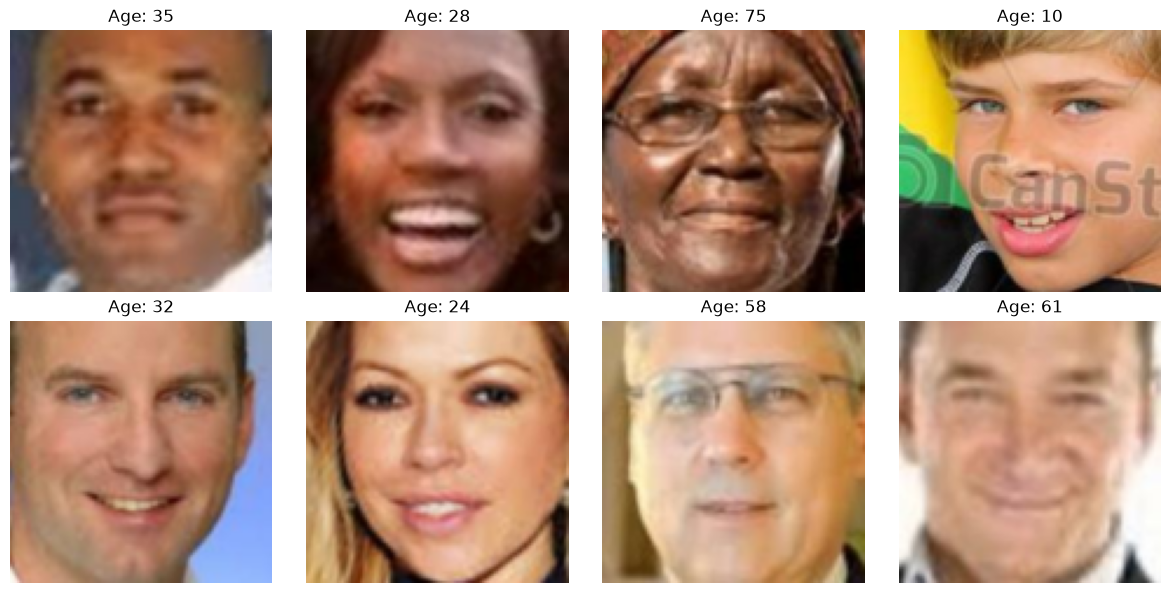

In [8]:
# 수정 금지

fig, axes = plt.subplots(2, 4, figsize=(12, 6))
for axis in axes.flat:
    axis.axis('off')
for axis, row in zip(axes.flat, train_rows[:8]):
    with Image.open(data_dir / row['filename']) as image:
        axis.imshow(image.convert('RGB'))
    axis.set_title(f"Age: {row['label']:g}")
plt.tight_layout()
plt.show()


# **답안 작성 셀 - 전처리**

### 주의!
* 전처리를 변경하면 Dataset/DataLoader 셀도 다시 실행하세요.
* 매 실험은 제공된 사전학습 가중치로부터 모델 학습이 진행되어야 합니다.


In [9]:
# 수정 가능
# 변환을 추가, 삭제, 조절할 수 있습니다.

shift = 0.80
shear = (50.0, 50.0)
tilt = 0.0
mask_probability = 0.95
mask_area = (0.02, 0.12)

train_transform = T.Compose([
    T.RandomHorizontalFlip(p=0.5),
    T.RandomAffine(degrees=0, translate=(shift, shift),
                   interpolation=InterpolationMode.BILINEAR, fill=fill),
    T.RandomAffine(degrees=0, shear=shear,
                   interpolation=InterpolationMode.BILINEAR, fill=fill),
    T.RandomRotation(degrees=tilt, interpolation=InterpolationMode.BILINEAR,
                     expand=False, fill=fill),
    T.ToTensor(),
    T.RandomErasing(p=mask_probability, scale=mask_area,
                    ratio=(0.5, 2.0), value=mean),
    T.Normalize(mean, std),
])


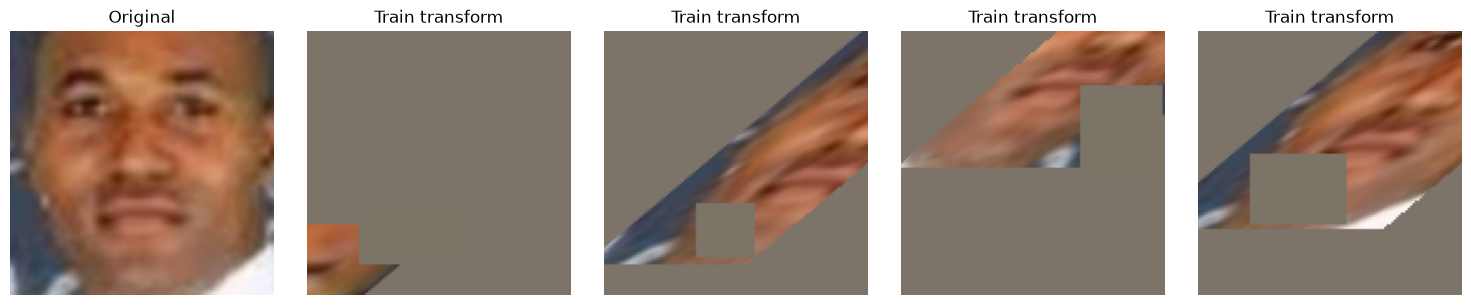

In [10]:
# 수정 가능
# 이미지 확인용 코드입니다. 일부를 수정하여 evaluation 데이터를 확인할 수도 있습니다.

with Image.open(data_dir / train_rows[0]['filename']) as image:
    sample_image = image.convert('RGB')
fig, axes = plt.subplots(1, 5, figsize=(15, 3))
axes[0].imshow(sample_image)
axes[0].set_title('Original')
for axis in axes[1:]:
    tensor = train_transform(sample_image)
    restored = tensor * torch.tensor(std)[:, None, None] + torch.tensor(mean)[:, None, None]
    axis.imshow(restored.permute(1, 2, 0).clamp(0, 1))
    axis.set_title('Train transform')
for axis in axes:
    axis.axis('off')
plt.tight_layout()
plt.show()


## 제공 모델: TinyViT 5M
### 아래 **모델 구조에 관한 코드는 수정하지 마세요.**

* 아래에는 TinyViT 5M의 구성 블록이 직접 구현되어 있습니다.
* 이 문제에서는 전체 모델을 학습하는 방식을 활용합니다.
  * Full fine-tuning


#### 입력을 특징 맵으로 바꾸기

* 입력 사이즈는 `(B, 3, 112, 112)` 여야 합니다.
* 기본값으로 코드에 구현되어 있습니다.


In [11]:
# 수정 금지

class ConvNorm(nn.Sequential):
    """Conv2d와 BatchNorm2d로 구성한 기본 블록."""
    def __init__(self, in_channels, out_channels, kernel_size=1,
                 stride=1, padding=0, groups=1, bn_weight=1.0):
        super().__init__()
        self.conv = nn.Conv2d(
            in_channels, out_channels, kernel_size,
            stride=stride, padding=padding, groups=groups, bias=False,
        )
        self.bn = nn.BatchNorm2d(out_channels)
        nn.init.constant_(self.bn.weight, bn_weight)
        nn.init.zeros_(self.bn.bias)


class PatchEmbed(nn.Module):
    """원본 입력을 특징 맵으로 변환: [B, 3, 112, 112] → [B, 64, 28, 28]."""
    def __init__(self, dim=64):
        super().__init__()
        self.conv1 = ConvNorm(3, dim // 2, 3, stride=2, padding=1)
        self.act = nn.GELU()
        self.conv2 = ConvNorm(dim // 2, dim, 3, stride=2, padding=1)

    def forward(self, x):
        x = self.conv1(x)
        x = self.act(x)
        return self.conv2(x)


#### 합성곱 블록과 해상도 축소

첫 stage는 MBConv를 사용합니다. 이후 stage는 Patch Merging으로 해상도를 줄입니다.


In [12]:
# 수정 금지

class MBConv(nn.Module):
    """Stage 0: 채널 확장 → depthwise convolution → 채널 축소."""
    def __init__(self, dim, expand_ratio=4):
        super().__init__()
        hidden_dim = dim * expand_ratio
        self.conv1 = ConvNorm(dim, hidden_dim)
        self.act1 = nn.GELU()
        self.conv2 = ConvNorm(hidden_dim, hidden_dim, 3,
                              padding=1, groups=hidden_dim)
        self.act2 = nn.GELU()
        self.conv3 = ConvNorm(hidden_dim, dim, bn_weight=0.0)
        self.act3 = nn.GELU()

    def forward(self, x):
        shortcut = x
        x = self.act1(self.conv1(x))
        x = self.act2(self.conv2(x))
        x = self.conv3(x)
        return self.act3(x + shortcut)


class ConvStage(nn.Module):
    def __init__(self, dim, depth):
        super().__init__()
        self.blocks = nn.Sequential(*[MBConv(dim) for _ in range(depth)])

    def forward(self, x):
        return self.blocks(x)


class PatchMerging(nn.Module):
    """해상도를 절반으로 줄이고 다음 stage의 채널 수로 변환."""
    def __init__(self, in_dim, out_dim):
        super().__init__()
        self.conv1 = ConvNorm(in_dim, out_dim)
        self.act1 = nn.GELU()
        self.conv2 = ConvNorm(out_dim, out_dim, 3, stride=2,
                              padding=1, groups=out_dim)
        self.act2 = nn.GELU()
        self.conv3 = ConvNorm(out_dim, out_dim)

    def forward(self, x):
        x = self.act1(self.conv1(x))
        x = self.act2(self.conv2(x))
        return self.conv3(x)


#### Window Attention과 MLP

각 window 내부의 위치 관계를 상대 위치 bias로 표현합니다.


In [13]:
# 수정 금지

class NormMLP(nn.Module):
    def __init__(self, dim, mlp_ratio=4):
        super().__init__()
        self.norm = nn.LayerNorm(dim)
        self.fc1 = nn.Linear(dim, dim * mlp_ratio)
        self.act = nn.GELU()
        self.fc2 = nn.Linear(dim * mlp_ratio, dim)

    def forward(self, x):
        x = self.norm(x)
        x = self.fc1(x)
        x = self.act(x)
        return self.fc2(x)


class WindowAttention(nn.Module):
    """작은 window 안에서 수행하는 multi-head self-attention."""
    def __init__(self, dim, num_heads, window_size):
        super().__init__()
        self.num_heads = num_heads
        self.head_dim = dim // num_heads
        self.scale = self.head_dim ** -0.5
        self.norm = nn.LayerNorm(dim)
        self.qkv = nn.Linear(dim, dim * 3)
        self.proj = nn.Linear(dim, dim)

        # window 내 두 위치 사이의 상대 거리에 따른 학습 가능한 bias
        coords = torch.stack(torch.meshgrid(
            torch.arange(window_size), torch.arange(window_size), indexing="ij"
        )).flatten(1)
        offsets = (coords[:, :, None] - coords[:, None, :]).abs()
        bias_indices = offsets[0] * window_size + offsets[1]
        self.register_buffer("attention_bias_idxs", bias_indices, persistent=False)
        self.attention_biases = nn.Parameter(
            torch.zeros(num_heads, window_size * window_size)
        )

    def forward(self, x):
        batch_size, num_tokens, dim = x.shape
        x = self.norm(x)

        # 체크포인트의 QKV 배치 순서: 각 head 안에 Q, K, V가 들어 있습니다.
        qkv = self.qkv(x).reshape(
            batch_size, num_tokens, self.num_heads, 3, self.head_dim
        )
        qkv = qkv.permute(3, 0, 2, 1, 4)
        q, k, v = qkv.unbind(dim=0)

        attention = (q * self.scale) @ k.transpose(-2, -1)
        bias = self.attention_biases[:, self.attention_bias_idxs]
        attention = (attention + bias.unsqueeze(0)).softmax(dim=-1)
        x = attention @ v
        x = x.transpose(1, 2).reshape(batch_size, num_tokens, dim)
        return self.proj(x)


#### Attention 블록과 Stage

특징 맵을 window로 나누고, 필요한 padding은 attention 후 제거합니다. 각 stage의 출력 크기는 28 × 28, 14 × 14, 7 × 7, 4 × 4입니다.


In [14]:
# 수정 금지

class TinyViTBlock(nn.Module):
    """Window attention → local convolution → MLP."""
    def __init__(self, dim, num_heads, window_size):
        super().__init__()
        self.window_size = window_size
        self.attn = WindowAttention(dim, num_heads, window_size)
        self.local_conv = ConvNorm(dim, dim, 3, padding=1, groups=dim)
        self.mlp = NormMLP(dim)

    def forward(self, x):
        # 이 블록 안에서는 [B, H, W, C] 순서로 처리합니다.
        batch_size, height, width, channels = x.shape
        shortcut = x
        window = self.window_size

        # 해상도가 window 크기의 배수가 아닐 때 오른쪽·아래쪽에 padding
        pad_h = (window - height % window) % window
        pad_w = (window - width % window) % window
        x = F.pad(x, (0, 0, 0, pad_w, 0, pad_h))
        padded_h, padded_w = height + pad_h, width + pad_w
        num_h, num_w = padded_h // window, padded_w // window

        # 이미지 → 여러 window
        x = x.reshape(batch_size, num_h, window, num_w, window, channels)
        x = x.transpose(2, 3).reshape(-1, window * window, channels)
        x = self.attn(x)

        # 여러 window → 이미지
        x = x.reshape(batch_size, num_h, num_w, window, window, channels)
        x = x.transpose(2, 3).reshape(batch_size, padded_h, padded_w, channels)
        x = x[:, :height, :width, :].contiguous()
        x = shortcut + x

        x = x.permute(0, 3, 1, 2)
        x = self.local_conv(x)
        x = x.flatten(2).transpose(1, 2)
        x = x + self.mlp(x)
        return x.reshape(batch_size, height, width, channels)


class TinyViTStage(nn.Module):
    def __init__(self, in_dim, out_dim, depth, num_heads, window_size):
        super().__init__()
        self.downsample = PatchMerging(in_dim, out_dim)
        self.blocks = nn.Sequential(*[
            TinyViTBlock(out_dim, num_heads, window_size) for _ in range(depth)
        ])

    def forward(self, x):
        x = self.downsample(x)
        x = x.permute(0, 2, 3, 1)
        x = self.blocks(x)
        return x.permute(0, 3, 1, 2)


#### 사전학습 가중치 불러오기

원래 1,000개 클래스의 가중치를 `strict=True`로 불러온 뒤 출력층을 나이 예측용 1개 출력으로 교체합니다. \
작은 window에 맞춰 상대 위치 bias만 보간하며 나머지 가중치는 그대로 사용합니다. 이 로딩 코드는 변경하지 마세요.


In [15]:
# 수정 금지
# 사전학습 가중치 로딩과 출력 head입니다.

from safetensors.torch import load_file


class ClassifierHead(nn.Module):
    def __init__(self, dim, num_classes):
        super().__init__()
        self.norm = nn.LayerNorm(dim, eps=1e-5)
        self.fc = nn.Linear(dim, num_classes)

    def forward(self, x):
        x = x.mean(dim=(2, 3))
        x = self.norm(x)
        return self.fc(x)


def load_pretrained_weights(model):
    """제공된 로컬 가중치를 읽고 상대 위치 bias만 입력 크기에 맞게 보간합니다."""
    path = Path('tiny_vit_5m_224.dist_in22k_ft_in1k.safetensors')
    if not path.is_file():
        raise FileNotFoundError(
            f'사전학습 가중치 파일을 찾을 수 없습니다: {path.resolve()}\n'
            '제공된 가중치 파일을 노트북과 같은 폴더에 두고, 작업 폴더를 해당 폴더로 맞추세요.'
        )
    weights = load_file(str(path))
    target = model.state_dict()
    for name, value in weights.items():
        if name.endswith('attention_biases') and value.shape != target[name].shape:
            num_heads, length = value.shape
            old_window = int(length ** 0.5)
            new_window = int(target[name].shape[1] ** 0.5)
            weights[name] = F.interpolate(
                value.float().reshape(1, num_heads, old_window, old_window),
                size=(new_window, new_window),
                mode='bicubic', antialias=True,
            ).reshape(num_heads, new_window * new_window)
    model.load_state_dict(weights, strict=True)


In [16]:
# 수정 금지
# 고정 모델입니다.

class UTKFaceModel(nn.Module):
    """사전학습 체크포인트와 호환되는 TinyViT 5M입니다."""
    def __init__(self):
        super().__init__()
        self.patch_embed = PatchEmbed(dim=64)
        self.stages = nn.Sequential(
            ConvStage(dim=64, depth=2),
            TinyViTStage(64, 128, depth=2, num_heads=4, window_size=3),
            TinyViTStage(128, 160, depth=6, num_heads=5, window_size=5),
            TinyViTStage(160, 320, depth=2, num_heads=10, window_size=3),
        )
        self.head = ClassifierHead(320, num_classes=1000)
        load_pretrained_weights(self)
        self.head.fc = nn.Linear(320, 1)

    def forward(self, x):
        x = self.patch_embed(x)
        x = self.stages[0](x)
        x = self.stages[1](x)
        x = self.stages[2](x)
        x = self.stages[3](x)
        x = x.mean(dim=(2, 3))
        x = self.head.norm(x)
        return self.head.fc(x)


## 제공 학습·평가 코드

* 각 epoch의 학습 Loss와 `val CS@10`을 기록하고 `val CS@10`이 가장 높은 모델을 저장합니다.
* 검증에서는 텐서 변환과 정규화만 적용하며 역전파를 수행하지 않습니다.
* 예측 나이는 반올림하거나 범위를 잘라내지 않고 평가합니다.
* `criterion`은 고정되어 있습니다. 수정할 수 없습니다.


In [17]:
# 수정 금지

def age_metrics(y_true, y_pred):
    error = np.asarray(y_pred, dtype=np.float64) - np.asarray(y_true, dtype=np.float64)
    return {
        "cs10": float((np.abs(error) <= 10).mean() * 100),
    }


def train_one_epoch(model, loader, criterion, optimizer):
    model.train()
    total_loss, within_ten, count = 0.0, 0, 0
    progress = tqdm(loader, desc="Train", leave=False)
    for images, ages in progress:
        images, ages = images.to(device), ages.to(device)
        optimizer.zero_grad()
        predictions = model(images).squeeze(1)
        loss = criterion(predictions, ages)
        loss.backward()
        optimizer.step()
        total_loss += loss.item() * len(ages)
        within_ten += ((predictions.detach() - ages).abs() <= 10).sum().item()
        count += len(ages)
        progress.set_postfix(loss=f"{total_loss / count:.3f}", cs10=f"{100 * within_ten / count:.2f}%")
    return total_loss / count, 100 * within_ten / count


@torch.no_grad()
def evaluate(model, loader, criterion):
    model.eval()
    total_loss = 0.0
    y_true, y_pred = [], []
    for images, ages in tqdm(loader, desc="Evaluate", leave=False):
        images, ages = images.to(device), ages.to(device)
        predictions = model(images).squeeze(1)
        total_loss += criterion(predictions, ages).item() * len(ages)
        y_true.extend(ages.cpu().tolist())
        y_pred.extend(predictions.cpu().tolist())
    metrics = age_metrics(y_true, y_pred)
    metrics["loss"] = total_loss / len(y_true)
    return metrics, np.asarray(y_true), np.asarray(y_pred)


### 고정된 학습 설정


In [18]:
# 수정 금지

EPOCHS = 25
batch_size = 64
learning_rate = 1e-4
weight_decay = 1e-4
checkpoint_path = output_dir / f'P1_2_{student_id}.pth'
history_path = output_dir / f'P1_2_{student_id}_history.csv'


### `criterion`

* `criterion(predictions, targets)`는 `(B,)` 형태의 실수 예측 나이와 정답 나이를 입력받습니다.
* 반환값은 유한한 배치 평균 스칼라 텐서여야 하며, 예측에 대해 역전파가 가능해야 합니다.
* `criterion` 부분과 `Loss` 부분은 고정된 값입니다. 수정하지 마세요.


In [19]:
# 수정 금지

criterion = nn.SmoothL1Loss(beta=5.0)


In [20]:
# 수정 금지

train_dataset = UTKFaceDataset(train_rows, train_transform)
val_dataset = UTKFaceDataset(val_rows, eval_transform)
train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=batch_size)


In [21]:
# 수정 금지

model = UTKFaceModel().to(device)
assert all(parameter.requires_grad for parameter in model.parameters())
optimizer = torch.optim.AdamW(model.parameters(), lr=learning_rate, weight_decay=weight_decay)
best_cs10 = -1.0
history = []
started = time.perf_counter()

for epoch in range(EPOCHS):
    train_loss, train_cs10 = train_one_epoch(model, train_loader, criterion, optimizer)
    metrics, _, _ = evaluate(model, val_loader, criterion)
    history.append({'epoch': epoch + 1, 'train_loss': train_loss, 'train_cs10': train_cs10,
                    **{f'val_{key}': value for key, value in metrics.items()}})
    if metrics['cs10'] > best_cs10:
        best_cs10 = metrics['cs10']
        torch.save({'model_state_dict': model.state_dict(), 'epoch': epoch + 1,
                    'val_cs10': best_cs10, 'train_transform': repr(train_transform)}, checkpoint_path)
    with history_path.open('w', encoding='utf-8', newline='') as file:
        writer = csv.DictWriter(file, fieldnames=list(history[0]))
        writer.writeheader()
        writer.writerows(history)
    print(f"{epoch + 1:2d}/{EPOCHS}  학습 Loss: {train_loss:.4f}  "
          f"검증 CS@10: {metrics['cs10']:.2f}%")

print(f'학습 시간: {time.perf_counter() - started:.1f}초')


Train:   0%|          | 0/94 [00:00<?, ?it/s]

Train:   0%|          | 0/94 [00:00<?, ?it/s, cs10=7.81%, loss=28.464]

Train:   1%|          | 1/94 [00:00<01:13,  1.27it/s, cs10=7.81%, loss=28.464]

Train:   1%|          | 1/94 [00:01<01:13,  1.27it/s, cs10=16.41%, loss=27.912]

Train:   2%|▏         | 2/94 [00:01<00:41,  2.22it/s, cs10=16.41%, loss=27.912]

Train:   2%|▏         | 2/94 [00:01<00:41,  2.22it/s, cs10=17.71%, loss=27.614]

... (5,142 outputs left out)

Evaluate:  83%|████████▎ | 20/24 [00:01<00:00, 11.79it/s]

Evaluate:  92%|█████████▏| 22/24 [00:01<00:00, 11.59it/s]

Evaluate: 100%|██████████| 24/24 [00:02<00:00, 12.57it/s]

25/25  학습 Loss: 9.6966  검증 CS@10: 16.60%
학습 시간: 592.6초


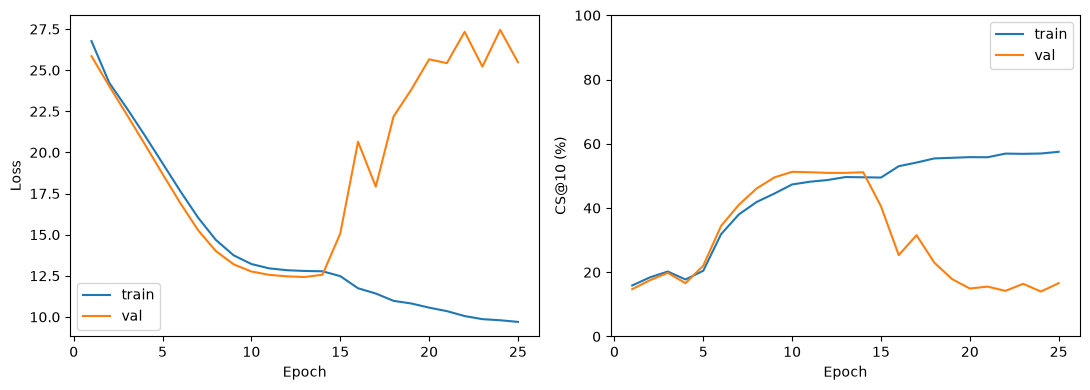

In [22]:
# 수정 금지

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for split in ['train', 'val']:
    axes[0].plot([row['epoch'] for row in history], [row[f'{split}_loss'] for row in history], label=split)
    axes[1].plot([row['epoch'] for row in history], [row[f'{split}_cs10'] for row in history], label=split)
axes[0].set_ylabel('Loss')
axes[1].set_ylabel('CS@10 (%)')
axes[1].set_ylim(0, 100)
for axis in axes:
    axis.set_xlabel('Epoch')
    axis.legend()
plt.tight_layout()
plt.show()


## 제출

아래 파일들을 제출하세요.
- 완성한 노트북 `.ipynb`
- Best 체크포인트 `outputs/P1_2_<수험번호>.pth`
- 학습 기록 `outputs/P1_2_<수험번호>_history.csv`

파일명에는 첫 셀의 수험번호가 자동으로 들어갑니다. 따로 이름을 바꿀 필요가 없습니다.
- 실제로 실행하는데 사용된 체크포인트 결과만 제출하세요.
- 실제로 실행한 validation 결과를 노트북에 남기세요.



<details>
<summary>모델 코드 출처와 라이선스</summary>

모델 구현은 Microsoft TinyViT와 timm v1.0.22를 참고한 수정본입니다.

원본: Microsoft Cream/TinyViT, timm (Ross Wightman 및 기여자). Apache License 2.0.

```text
                                 Apache License
                           Version 2.0, January 2004
                        http://www.apache.org/licenses/

   TERMS AND CONDITIONS FOR USE, REPRODUCTION, AND DISTRIBUTION

   1. Definitions.

      "License" shall mean the terms and conditions for use, reproduction,
      and distribution as defined by Sections 1 through 9 of this document.

      "Licensor" shall mean the copyright owner or entity authorized by
      the copyright owner that is granting the License.

      "Legal Entity" shall mean the union of the acting entity and all
      other entities that control, are controlled by, or are under common
      control with that entity. For the purposes of this definition,
      "control" means (i) the power, direct or indirect, to cause the
      direction or management of such entity, whether by contract or
      otherwise, or (ii) ownership of fifty percent (50%) or more of the
      outstanding shares, or (iii) beneficial ownership of such entity.

      "You" (or "Your") shall mean an individual or Legal Entity
      exercising permissions granted by this License.

      "Source" form shall mean the preferred form for making modifications,
      including but not limited to software source code, documentation
      source, and configuration files.

      "Object" form shall mean any form resulting from mechanical
      transformation or translation of a Source form, including but
      not limited to compiled object code, generated documentation,
      and conversions to other media types.

      "Work" shall mean the work of authorship, whether in Source or
      Object form, made available under the License, as indicated by a
      copyright notice that is included in or attached to the work
      (an example is provided in the Appendix below).

      "Derivative Works" shall mean any work, whether in Source or Object
      form, that is based on (or derived from) the Work and for which the
      editorial revisions, annotations, elaborations, or other modifications
      represent, as a whole, an original work of authorship. For the purposes
      of this License, Derivative Works shall not include works that remain
      separable from, or merely link (or bind by name) to the interfaces of,
      the Work and Derivative Works thereof.

      "Contribution" shall mean any work of authorship, including
      the original version of the Work and any modifications or additions
      to that Work or Derivative Works thereof, that is intentionally
      submitted to Licensor for inclusion in the Work by the copyright owner
      or by an individual or Legal Entity authorized to submit on behalf of
      the copyright owner. For the purposes of this definition, "submitted"
      means any form of electronic, verbal, or written communication sent
      to the Licensor or its representatives, including but not limited to
      communication on electronic mailing lists, source code control systems,
      and issue tracking systems that are managed by, or on behalf of, the
      Licensor for the purpose of discussing and improving the Work, but
      excluding communication that is conspicuously marked or otherwise
      designated in writing by the copyright owner as "Not a Contribution."

      "Contributor" shall mean Licensor and any individual or Legal Entity
      on behalf of whom a Contribution has been received by Licensor and
      subsequently incorporated within the Work.

   2. Grant of Copyright License. Subject to the terms and conditions of
      this License, each Contributor hereby grants to You a perpetual,
      worldwide, non-exclusive, no-charge, royalty-free, irrevocable
      copyright license to reproduce, prepare Derivative Works of,
      publicly display, publicly perform, sublicense, and distribute the
      Work and such Derivative Works in Source or Object form.

   3. Grant of Patent License. Subject to the terms and conditions of
      this License, each Contributor hereby grants to You a perpetual,
      worldwide, non-exclusive, no-charge, royalty-free, irrevocable
      (except as stated in this section) patent license to make, have made,
      use, offer to sell, sell, import, and otherwise transfer the Work,
      where such license applies only to those patent claims licensable
      by such Contributor that are necessarily infringed by their
      Contribution(s) alone or by combination of their Contribution(s)
      with the Work to which such Contribution(s) was submitted. If You
      institute patent litigation against any entity (including a
      cross-claim or counterclaim in a lawsuit) alleging that the Work
      or a Contribution incorporated within the Work constitutes direct
      or contributory patent infringement, then any patent licenses
      granted to You under this License for that Work shall terminate
      as of the date such litigation is filed.

   4. Redistribution. You may reproduce and distribute copies of the
      Work or Derivative Works thereof in any medium, with or without
      modifications, and in Source or Object form, provided that You
      meet the following conditions:

      (a) You must give any other recipients of the Work or
          Derivative Works a copy of this License; and

      (b) You must cause any modified files to carry prominent notices
          stating that You changed the files; and

      (c) You must retain, in the Source form of any Derivative Works
          that You distribute, all copyright, patent, trademark, and
          attribution notices from the Source form of the Work,
          excluding those notices that do not pertain to any part of
          the Derivative Works; and

      (d) If the Work includes a "NOTICE" text file as part of its
          distribution, then any Derivative Works that You distribute must
          include a readable copy of the attribution notices contained
          within such NOTICE file, excluding those notices that do not
          pertain to any part of the Derivative Works, in at least one
          of the following places: within a NOTICE text file distributed
          as part of the Derivative Works; within the Source form or
          documentation, if provided along with the Derivative Works; or,
          within a display generated by the Derivative Works, if and
          wherever such third-party notices normally appear. The contents
          of the NOTICE file are for informational purposes only and
          do not modify the License. You may add Your own attribution
          notices within Derivative Works that You distribute, alongside
          or as an addendum to the NOTICE text from the Work, provided
          that such additional attribution notices cannot be construed
          as modifying the License.

      You may add Your own copyright statement to Your modifications and
      may provide additional or different license terms and conditions
      for use, reproduction, or distribution of Your modifications, or
      for any such Derivative Works as a whole, provided Your use,
      reproduction, and distribution of the Work otherwise complies with
      the conditions stated in this License.

   5. Submission of Contributions. Unless You explicitly state otherwise,
      any Contribution intentionally submitted for inclusion in the Work
      by You to the Licensor shall be under the terms and conditions of
      this License, without any additional terms or conditions.
      Notwithstanding the above, nothing herein shall supersede or modify
      the terms of any separate license agreement you may have executed
      with Licensor regarding such Contributions.

   6. Trademarks. This License does not grant permission to use the trade
      names, trademarks, service marks, or product names of the Licensor,
      except as required for reasonable and customary use in describing the
      origin of the Work and reproducing the content of the NOTICE file.

   7. Disclaimer of Warranty. Unless required by applicable law or
      agreed to in writing, Licensor provides the Work (and each
      Contributor provides its Contributions) on an "AS IS" BASIS,
      WITHOUT WARRANTIES OR CONDITIONS OF ANY KIND, either express or
      implied, including, without limitation, any warranties or conditions
      of TITLE, NON-INFRINGEMENT, MERCHANTABILITY, or FITNESS FOR A
      PARTICULAR PURPOSE. You are solely responsible for determining the
      appropriateness of using or redistributing the Work and assume any
      risks associated with Your exercise of permissions under this License.

   8. Limitation of Liability. In no event and under no legal theory,
      whether in tort (including negligence), contract, or otherwise,
      unless required by applicable law (such as deliberate and grossly
      negligent acts) or agreed to in writing, shall any Contributor be
      liable to You for damages, including any direct, indirect, special,
      incidental, or consequential damages of any character arising as a
      result of this License or out of the use or inability to use the
      Work (including but not limited to damages for loss of goodwill,
      work stoppage, computer failure or malfunction, or any and all
      other commercial damages or losses), even if such Contributor
      has been advised of the possibility of such damages.

   9. Accepting Warranty or Additional Liability. While redistributing
      the Work or Derivative Works thereof, You may choose to offer,
      and charge a fee for, acceptance of support, warranty, indemnity,
      or other liability obligations and/or rights consistent with this
      License. However, in accepting such obligations, You may act only
      on Your own behalf and on Your sole responsibility, not on behalf
      of any other Contributor, and only if You agree to indemnify,
      defend, and hold each Contributor harmless for any liability
      incurred by, or claims asserted against, such Contributor by reason
      of your accepting any such warranty or additional liability.

   END OF TERMS AND CONDITIONS

   APPENDIX: How to apply the Apache License to your work.

      To apply the Apache License to your work, attach the following
      boilerplate notice, with the fields enclosed by brackets "{}"
      replaced with your own identifying information. (Don't include
      the brackets!)  The text should be enclosed in the appropriate
      comment syntax for the file format. We also recommend that a
      file or class name and description of purpose be included on the
      same "printed page" as the copyright notice for easier
      identification within third-party archives.

   Copyright 2019 Ross Wightman

   Licensed under the Apache License, Version 2.0 (the "License");
   you may not use this file except in compliance with the License.
   You may obtain a copy of the License at

       http://www.apache.org/licenses/LICENSE-2.0

   Unless required by applicable law or agreed to in writing, software
   distributed under the License is distributed on an "AS IS" BASIS,
   WITHOUT WARRANTIES OR CONDITIONS OF ANY KIND, either express or implied.
   See the License for the specific language governing permissions and
   limitations under the License.

```
